# E2：相關性特徵選擇實驗

研究問題：固定 C=0.001，減少特徵是否改善 logistic regression 的開發 CV AUC？

- k = 5、10、20、50、150。
- Pipeline：CorrelationSelector → StandardScaler → LogisticRegression。
- 分層五折、十次重複，split seeds 0–9。
- 特徵選擇只在各折訓練資料上擬合。

此 notebook 讀取已完成的實驗，不訓練模型、不上傳 Kaggle。
先確認 k=150 重現原本基準，再比較其他 k。


In [1]:
from pathlib import Path
from collections import Counter
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in (current, *current.parents)
     if (path / "configs").is_dir() and (path / "outputs" / "results").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open the notebook inside the project directory.")

RESULTS_DIR = PROJECT_ROOT / "outputs" / "results"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures" / "e2_correlation_selection"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
K_VALUES = [5, 10, 20, 50, 150]
BASELINE_DIR = RESULTS_DIR / "logistic_c_0_001"

print(f"Project root: {PROJECT_ROOT}")


Project root: /Users/moli/Documents/coding/DSAI4203_Project/small_sample_classification


## 1. 載入及核對結果

檢查設定、實際切分索引、各次重複分數與選中特徵紀錄。
缺少任何一組輸出時會停止，而不是默默省略該設定。
相同索引不代表原始資料未改動：資料雜湊和程式版本仍需另外保存。


In [2]:
required_files = [
    "config.json", "summary.json", "fold_scores.csv", "repeat_scores.csv",
    "split_indices.json", "selected_features.json",
]
missing = [
    str(RESULTS_DIR / f"e2_correlation_k_{k}" / filename)
    for k in K_VALUES for filename in required_files
    if not (RESULTS_DIR / f"e2_correlation_k_{k}" / filename).is_file()
]
if missing:
    raise FileNotFoundError("Missing E2 outputs:\n" + "\n".join(missing))

baseline_config = json.loads((BASELINE_DIR / "config.json").read_text(encoding="utf-8"))
baseline_splits = json.loads((BASELINE_DIR / "split_indices.json").read_text(encoding="utf-8"))
baseline_fold_scores = pd.read_csv(BASELINE_DIR / "fold_scores.csv")

repeat_tables = []
fold_tables = {}
selection_records = {}

for k in K_VALUES:
    directory = RESULTS_DIR / f"e2_correlation_k_{k}"
    config = json.loads((directory / "config.json").read_text(encoding="utf-8"))
    summary = json.loads((directory / "summary.json").read_text(encoding="utf-8"))
    splits = json.loads((directory / "split_indices.json").read_text(encoding="utf-8"))
    features = json.loads((directory / "selected_features.json").read_text(encoding="utf-8"))
    repeats = pd.read_csv(directory / "repeat_scores.csv")
    folds = pd.read_csv(directory / "fold_scores.csv")

    if config["feature_selection_k"] != k or config["regularization_c"] != 0.001:
        raise ValueError(f"Unexpected selector or C setting: k={k}")
    if config["n_splits"] != 5 or config["split_seeds"] != list(range(10)):
        raise ValueError(f"Unexpected validation scheme: k={k}")
    for key in ["model_name", "regularization_c", "max_iter", "n_splits", "split_seeds"]:
        if config[key] != baseline_config[key]:
            raise ValueError(f"Baseline setting mismatch: {key}, k={k}")
    if splits["splits"] != baseline_splits["splits"]:
        raise ValueError(f"Split assignments differ: k={k}")
    if splits["feature_names"] != baseline_splits["feature_names"]:
        raise ValueError(f"Input feature names/order differ: k={k}")
    if summary["aggregation"] != "mean_fold_auc_per_repeat":
        raise ValueError(f"Unexpected aggregation: k={k}")

    keys = ["repeat", "split_seed", "fold"]
    pd.testing.assert_frame_equal(folds[keys], baseline_fold_scores[keys])
    if len(folds) != 50 or folds[keys].duplicated().any():
        raise ValueError(f"Incomplete or duplicate fold results: k={k}")
    if len(repeats) != 10 or repeats["split_seed"].duplicated().any():
        raise ValueError(f"Incomplete or duplicate repetitions: k={k}")
    if sorted(repeats["split_seed"].tolist()) != list(range(10)):
        raise ValueError(f"Unexpected seeds: k={k}")
    if not repeats["n_folds"].eq(5).all():
        raise ValueError(f"Unexpected fold count: k={k}")
    if not folds["valid_auc"].between(0, 1).all():
        raise ValueError(f"Invalid fold AUC: k={k}")
    if not repeats["mean_auc"].between(0, 1).all():
        raise ValueError(f"Invalid repeat AUC: k={k}")

    calculated = folds.groupby(["repeat", "split_seed"], as_index=False)["valid_auc"].mean()
    matched = repeats.merge(calculated, on=["repeat", "split_seed"], validate="one_to_one")
    if len(matched) != 10:
        raise ValueError(f"Repetition identifiers do not match folds: k={k}")
    np.testing.assert_allclose(matched["mean_auc"], matched["valid_auc"], atol=1e-12, rtol=0)
    np.testing.assert_allclose(repeats["mean_auc"].mean(), summary["mean_auc"], atol=1e-12, rtol=0)
    np.testing.assert_allclose(repeats["mean_auc"].std(ddof=1), summary["std_auc"], atol=1e-12, rtol=0)

    expected_keys = {tuple(row) for row in folds[keys].itertuples(index=False, name=None)}
    feature_keys = [(record["repeat"], record["split_seed"], record["fold"]) for record in features]
    if len(feature_keys) != 50 or set(feature_keys) != expected_keys:
        raise ValueError(f"Incomplete selection records: k={k}")
    input_names = set(splits["feature_names"])
    for record in features:
        names = record["selected_features"]
        if record["k"] != k or len(names) != k or len(set(names)) != k:
            raise ValueError(f"Invalid selected feature count: k={k}")
        if not set(names).issubset(input_names):
            raise ValueError(f"Unknown selected features: k={k}")

    repeat_tables.append(repeats.assign(k=k))
    fold_tables[k] = folds
    selection_records[k] = features

np.testing.assert_allclose(
    fold_tables[150]["valid_auc"], baseline_fold_scores["valid_auc"],
    atol=1e-12, rtol=0,
)
repeat_scores = pd.concat(repeat_tables, ignore_index=True)
print("Validation passed: identical splits; k=150 reproduces the baseline.")


Validation passed: identical splits; k=150 reproduces the baseline.


## 2. 摘要與配對差值

每次重複先取五折平均，再計算十次平均值和樣本標準差。
配對差值 = 該 k 的重複平均 AUC − k=150 的同次重複平均 AUC。
正值代表該次切分中，特徵選擇優於全部特徵。


In [3]:
summary_table = (
    repeat_scores.groupby("k", as_index=False)
    .agg(mean_auc=("mean_auc", "mean"), std_auc=("mean_auc", "std"),
         min_auc=("mean_auc", "min"), max_auc=("mean_auc", "max"),
         n_repeats=("mean_auc", "count"))
    .sort_values("k").reset_index(drop=True)
)
control = repeat_scores.loc[repeat_scores["k"].eq(150), ["repeat", "split_seed", "mean_auc"]].rename(
    columns={"mean_auc": "control_auc"}
)
paired = repeat_scores.merge(control, on=["repeat", "split_seed"], validate="many_to_one")
paired["difference"] = paired["mean_auc"] - paired["control_auc"]
paired_summary = (
    paired.groupby("k", as_index=False)
    .agg(mean_difference=("difference", "mean"), sd_difference=("difference", "std"),
         improved_repeats=("difference", lambda x: int((x > 1e-12).sum())),
         worse_repeats=("difference", lambda x: int((x < -1e-12).sum())),
         tied_repeats=("difference", lambda x: int((x.abs() <= 1e-12).sum())))
)
comparison = summary_table.merge(paired_summary, on="k", validate="one_to_one")
display(comparison.round(6))
comparison.to_csv(FIGURES_DIR / "e2_comparison.csv", index=False)
paired.to_csv(FIGURES_DIR / "e2_paired_repeat_scores.csv", index=False)


,k,mean_auc,std_auc,min_auc,max_auc,n_repeats,mean_difference,sd_difference,improved_repeats,worse_repeats,tied_repeats
0,5,0.795349,0.006414,0.786194,0.807110,10,0.001350,0.008531,6,4,0
1,10,0.808618,0.008244,0.793707,0.823294,10,0.014619,0.009427,10,0,0
2,20,0.798767,0.008428,0.787815,0.809618,10,0.004769,0.010562,6,4,0
3,50,0.797398,0.008861,0.784584,0.809713,10,0.003400,0.008265,4,6,0
4,150,0.793999,0.009091,0.779321,0.808694,10,0.000000,0.000000,0,0,10


## 3. 平均 AUC 與重複軌跡

誤差棒為平均值 ± 一個跨重複樣本標準差，不是信賴區間。
右圖每條彩色線代表相同切分種子；折線不表示未測試的 k 值也有對應表現。


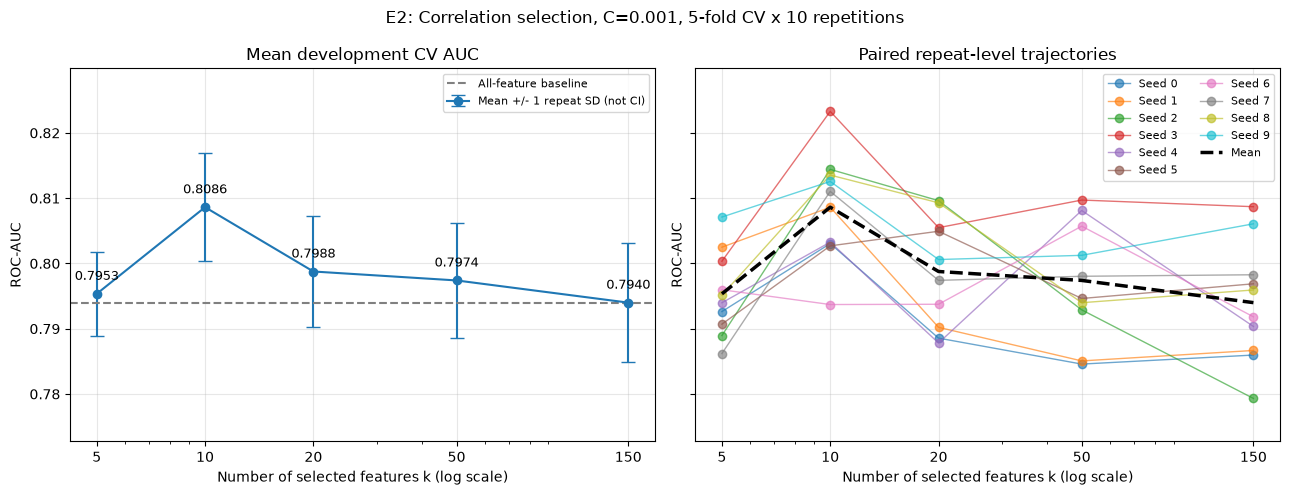

In [4]:
def save_figure(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIGURES_DIR / f"{name}.pdf", bbox_inches="tight")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
axes[0].errorbar(summary_table["k"], summary_table["mean_auc"],
                 yerr=summary_table["std_auc"], fmt="o-", capsize=5,
                 label="Mean +/- 1 repeat SD (not CI)")
axes[0].axhline(summary_table.loc[summary_table["k"].eq(150), "mean_auc"].iloc[0],
                 color="gray", linestyle="--", label="All-feature baseline")
for row in summary_table.itertuples(index=False):
    axes[0].annotate(f"{row.mean_auc:.4f}", (row.k, row.mean_auc),
                     xytext=(0, 10), textcoords="offset points", ha="center", fontsize=9)
axes[0].set_title("Mean development CV AUC")
axes[0].legend(fontsize=8)
for seed, group in repeat_scores.groupby("split_seed"):
    group = group.sort_values("k")
    axes[1].plot(group["k"], group["mean_auc"], "o-", alpha=0.65, linewidth=1, label=f"Seed {seed}")
axes[1].plot(summary_table["k"], summary_table["mean_auc"], "k--", linewidth=2.5, label="Mean")
axes[1].set_title("Paired repeat-level trajectories")
axes[1].legend(fontsize=8, ncol=2)
for ax in axes:
    ax.set_xscale("log")
    ax.set_xticks(K_VALUES)
    ax.set_xticklabels([str(k) for k in K_VALUES])
    ax.set_xlabel("Number of selected features k (log scale)")
    ax.set_ylabel("ROC-AUC")
    ax.grid(alpha=0.3)
    ax.margins(y=0.15)
fig.suptitle("E2: Correlation selection, C=0.001, 5-fold CV x 10 repetitions")
fig.tight_layout()
save_figure(fig, "e2_k_vs_auc")
plt.show()


## 4. 相對全部特徵的配對差值

每個點是一個重複驗證的差值。黑色菱形是十次差值的平均。
這些重複共用相同觀察值，不是十個獨立資料集；此圖不提供顯著性檢定。


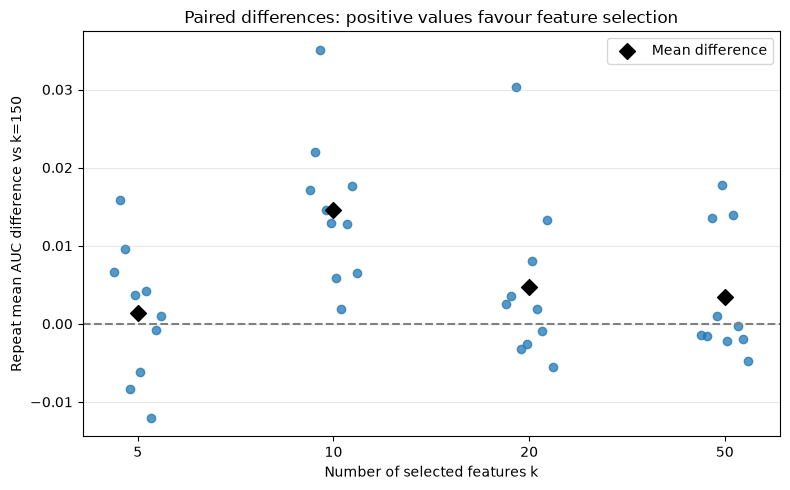

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
candidates = [5, 10, 20, 50]
for position, k in enumerate(candidates):
    values = paired.loc[paired["k"].eq(k)].sort_values("split_seed")["difference"].to_numpy()
    offsets = np.linspace(-0.12, 0.12, len(values))
    ax.scatter(position + offsets, values, alpha=0.75, color="tab:blue")
    ax.scatter(position, values.mean(), marker="D", color="black", s=65, zorder=3,
               label="Mean difference" if position == 0 else None)
ax.axhline(0, color="gray", linestyle="--")
ax.set_xticks(range(len(candidates)))
ax.set_xticklabels([str(k) for k in candidates])
ax.set_xlabel("Number of selected features k")
ax.set_ylabel("Repeat mean AUC difference vs k=150")
ax.set_title("Paired differences: positive values favour feature selection")
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
save_figure(fig, "e2_paired_differences")
plt.show()


## 5. 特徵選擇頻率（描述性檢查）

以下計算每個特徵在 50 個訓練折中被選中的比例。
這不是 bootstrap 穩定性研究，也不是獨立抽樣的選擇機率。
訓練折互相重疊；頻率高也不直接證明該特徵有因果或額外預測價值。


In [6]:
frequency_rows = []
for k in K_VALUES:
    counts = Counter(name for record in selection_records[k] for name in record["selected_features"])
    for name in baseline_splits["feature_names"]:
        frequency_rows.append({"k": k, "feature": name, "selected_folds": counts[name],
                               "total_folds": len(selection_records[k]),
                               "selection_frequency": counts[name] / len(selection_records[k])})
frequencies = pd.DataFrame(frequency_rows)
frequencies.to_csv(FIGURES_DIR / "e2_feature_selection_frequencies.csv", index=False)

display_k = 10
print(f"Top 20 selection frequencies for k={display_k}")
display(frequencies.loc[frequencies["k"].eq(display_k)].sort_values(
    ["selection_frequency", "feature"], ascending=[False, True]
).head(20).reset_index(drop=True))
print(f"Figures and tables saved to: {FIGURES_DIR}")


Top 20 selection frequencies for k=10


,k,feature,selected_folds,total_folds,selection_frequency
0,10,100,50,50,1.00
1,10,112,50,50,1.00
2,10,17,50,50,1.00
3,10,46,50,50,1.00
4,10,49,50,50,1.00
5,10,77,50,50,1.00
6,10,80,50,50,1.00
7,10,98,50,50,1.00
8,10,67,26,50,0.52
9,10,8,11,50,0.22


Figures and tables saved to: /Users/moli/Documents/coding/DSAI4203_Project/small_sample_classification/outputs/figures/e2_correlation_selection


## 6. 結論紀錄（執行後填寫）

- 最高平均開發 AUC 的 k：待填。
- 相對 k=150 的平均配對改善：待填。
- 十次配對比較中改善／下降／相同的次數：待填。
- 改善是否一致、是否只有少數切分特別突出：待填。
- 下一步：保留全部特徵／保留哪些 k 作 E3 候選，並寫明理由。

本輪只比較固定 C=0.001 的特徵選擇方案。
不能據此推斷其他 C 下的最佳 k，也不能將選出的最高分當成獨立泛化估計。
先完成分析，不根據單次公開榜分數追加大量 k 值。
